# Classical ML Models — Guangyu

Working file for **Section 2** of `main.ipynb`: majority baseline, Logistic Regression, Decision Tree, Random Forest.

Every model runs over **4 cutoffs × 3 feature sets** with the same protocol: tune on validation → refit on train+val → test once.

## Plan & hints *(working notes — don't copy into `main.ipynb`)*

### Order of work — freeze Tue 14 Oct
1. 2.0 Config (data + features) and the training loop; test LR / DT / RF at **cutoff 24 only**
2. Sanity-check numbers (below), then switch to all 4 cutoffs
3. Each model section: train & tune → results table → tuning curve
4. 2.5 Summary: combined table + best model → hand to whoever builds Section 4

### Rules
- Use `a2_common` for split, preprocessing and metrics — never a custom split or scaler
- Tune on **val** only; refit on train+val; touch **test once** per cell
- Pass `SEED` to every estimator
- Each cutoff is a separate dataset — **never pool cutoffs**
- Training happens only in 2.1–2.4; 2.5 only combines results already produced

### Feature sets
| Name | Definition |
|---|---|
| `background` | `A2.feature_cols("baseline")` (14) |
| `behaviour` | `engineered` minus `baseline` (38) |
| `all` | `A2.feature_cols("engineered")` (52) |

### Models & grids (method: grid search, select on val macro-F1)
| Model | Bias / variance | Grid |
|---|---|---|
| Majority baseline | — | `strategy` = most_frequent only; one feature set |
| Logistic Regression | high bias, low variance | `C` ∈ {0.0001, 0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10} |
| Decision Tree | low bias, high variance | `max_depth` ∈ {2, 4, 6, 8, 10, 15, 20, None} |
| Random Forest | low bias, reduced variance (bagging) | `min_samples_leaf` ∈ {1, 5, 10, 20, 50} |

### `run_experiment()` contract
- For each cutoff × feature set: try grid → best on val → refit train+val → score test → one row
- Returns `(rows, curve, best_pipe)`:
  - `rows` — test scores for every cell
  - `curve` — `{value: val macro-F1}`, **cutoff 24 + all** only (explains the chosen value)
  - `best_pipe` — fitted best pipeline, **cutoff 24 + all** only (predictions)
- Each section keeps its own three outputs and shows its own results + tuning curve; 2.5 combines them
- Agree the signature with Xinyan so the MLP plugs into the same loop

### Sanity checks *(verified 12 Oct with scikit-learn 1.9.1, pandas 3.0.6)*
- `SPLITS[24]` sizes: **16,688 / 5,563 / 5,562** (= `processed/splits_summary.csv`)
- Baseline test macro-F1: **0.3428 / 0.3562 / 0.3685 / 0.3831** (cutoffs 0 / 24 / 60 / 120)
- LR at cutoff 24: background **0.5977** (C=0.03), behaviour **0.6744** (C=1), all **0.7072** (C=0.03) (= `processed/lr_test_results.csv`)
- `rq1_cutoff_sweep.csv` and the split table in `docs/data-layer.md` come from an **older, different split** — don't compare against them
- ROC-AUC > 0.95 → suspect leakage before celebrating

### How the outputs answer the RQs
- **RQ1** (how early?): `all` row across cutoffs, lift over each cutoff's baseline, model vs model
- **RQ2** (behaviour vs background?): compare the 3 feature sets within each cutoff; gain = all − background; check it holds for every model
- Tuning curves → chosen-value explanation + bias–variance (theory–practice)
- Predictions → confusion matrix + specific cases (error analysis)

### Open items to confirm with the group
- **Everyone uses scikit-learn 1.9.1** — a different version can produce a different split and different numbers
- My LR run replaces Wai Chun's `lr_*` / `rq1_*` CSVs (they used two different `C` grids, and the sweep used an older split)
- Add `behaviour` set to the shared definitions; rename feature set `baseline` → `background` in `main.ipynb`
- Model choice LR / DT / RF (fallback: swap RF for KNN if DT+RF is seen as too similar)
- README model-choice edits are still uncommitted

## 0. Setup

Imports, `SEED`, cutoffs, and the shared harness from `a2_common`.

In [1]:
# import tool libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# import sklearn models
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression # Model 1
from sklearn.tree import DecisionTreeClassifier # Model 2
from sklearn.ensemble import RandomForestClassifier # Model 3

# import helper for processing data
import a2_common as A2

# set global variables
SEED = A2.SEED
CUTOFF_DAYS = A2.CUTOFF_DAYS # [0, 24, 60, 120]


## 2.0 Config

Data and features only: the three feature sets (background / behaviour / all) and the train/val/test split for each cutoff.

In [2]:
# one train/val/test split per cutoff (RQ1), grouped by student
SPLITS = {cut: A2.make_splits(A2.load_table(cut)) for cut in CUTOFF_DAYS}

# define feature groups: background, behaviour, all for RQ2
FEATURE_SETS = {
    "background": A2.feature_cols("baseline"),
    "behaviour": A2.feature_cols("behaviour"),
    "all": A2.feature_cols("engineered")
}

### Training loop — `run_experiment()`

For each cutoff × feature set: tune on val → refit on train+val → test once. Built on `A2.score_model`. Returns `(rows, curve, best_pipe)`.

*Moves to §1.5 (shared harness) in `main.ipynb`, so the MLP in Section 3 uses the same loop.*

In [3]:
# run experiment for a given model, parameter (and values), cutoffs, and feature sets
def run_experiment(name, model, param, values, cutoffs=CUTOFF_DAYS, feature_sets=None):
    rows, curve, best_pipe = [], {}, None
    # using cutoffs to answer RQ1
    for cut in cutoffs:
        train, val, test = SPLITS[cut]
        train_val = pd.concat([train, val], ignore_index=True)
        for fs, cols in (feature_sets or FEATURE_SETS).items():
            # using feature sets to answer RQ2
            val_f1 = {}
            for v in values:
                # set model parameters
                m = clone(model).set_params(**{param: v})
                # fit on train, macro-F1 on val
                val_f1[v] = A2.score_model(m, cols, train, val)[1]["macro_f1"]
            best = max(val_f1, key=val_f1.get)

            # refit best on train+val, score test once
            m = clone(model).set_params(**{param: best})
            pipe, scores = A2.score_model(m, cols, train_val, test)
            rows.append({"model": name, "cutoff": cut, "feature_set": fs,
                         "best_param": f"{param}={best}", **scores})
            if cut == 24 and fs == "all":
                curve = val_f1
                best_pipe = pipe
    return rows, curve, best_pipe

### Plot helper — `plot_curve()`

Draws validation macro-F1 against one hyperparameter and marks the chosen value. Used by 2.2.3, 2.3.3 and 2.4.3.

In [4]:
# plot the tuning curve for a given model
# the curve is a dict of {param_value: validation macro_f1}
# the curve is generated on the validation set for cutoff=24 and feature_set="all"
def plot_curve(name, curve, param):
    # text labels for x-axis
    xaxis = [str(v) for v in curve]
    # find the chosen value with the same rule as run_experiment()
    best = max(curve, key=curve.get)
    plt.figure(figsize=(6, 4))
    plt.plot(xaxis, list(curve.values()), marker='o')
    # mark the chosen value, so the plot explains why it was picked
    plt.axvline(list(curve).index(best), linestyle='--', color='grey',
                label=f"chosen {param} = {best}")
    plt.title(f"{name} tuning curve (cutoff 24, all features)")
    plt.xlabel(param)
    plt.ylabel("Validation macro-F1")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid()
    plt.show()

## 2.1 Majority-class baseline

`DummyClassifier(strategy="most_frequent")`, no tuning. The reference every model must beat.

In [5]:
# Run experiment for baseline_model
base_rows, _, _ = run_experiment("Baseline",
                                 DummyClassifier(random_state=SEED),
                                 "strategy", ["most_frequent"],
                                 feature_sets={"—": FEATURE_SETS["background"]})
pd.DataFrame(base_rows)

,model,cutoff,feature_set,best_param,accuracy,precision,recall,f1,macro_f1,roc_auc
0,Baseline,0,—,strategy=most_frequent,0.5216,0.0,0.0,0.0,0.3428,0.5
1,Baseline,24,—,strategy=most_frequent,0.5532,0.0,0.0,0.0,0.3562,0.5
2,Baseline,60,—,strategy=most_frequent,0.5836,0.0,0.0,0.0,0.3685,0.5
3,Baseline,120,—,strategy=most_frequent,0.6210,0.0,0.0,0.0,0.3831,0.5


## 2.2 Logistic Regression

High bias, low variance. Tune `C`.

### 2.2.1 Train & tune

All 4 cutoffs × 3 feature sets; `C` chosen on validation macro-F1, test scored once per cell.

In [6]:
# run experiment for logistic regression
# tune hyperparameter C (inverse of regularization strength) on validation set
log_rows, log_curve, log_pipe = run_experiment(
    "LogisticRegression",
    LogisticRegression(random_state=SEED, max_iter=2000),
    "C", [0.0001, 0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10])

### 2.2.2 Results

Test macro-F1 by feature set × cutoff (compare with the baseline in 2.1).

In [7]:
# visualize the results of feature set x cutoff experiments results
log_table = pd.DataFrame(log_rows).pivot(index="cutoff",
                                        columns="feature_set",
                                        values="macro_f1")
display(log_table)

feature_set,all,background,behaviour
cutoff,,,
0,0.6565,0.6117,0.6198
24,0.7072,0.5977,0.6744
60,0.7519,0.5955,0.7330
120,0.7908,0.5714,0.7735


### 2.2.3 Tuning curve

Validation macro-F1 against `C` at cutoff 24, all features. Explains the chosen value.

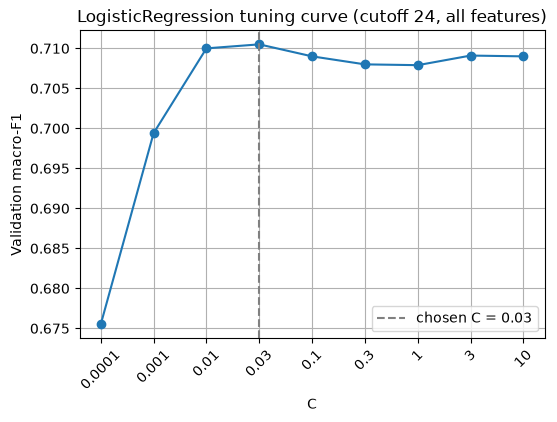

feature_set,all,background,behaviour
cutoff,,,
0,C=0.3,C=0.1,C=0.001
24,C=0.03,C=0.03,C=1
60,C=1,C=10,C=0.1
120,C=10,C=1,C=10


In [8]:
# visualize the tuning curve for the model with cutoff=24 and feature_set="all"
plot_curve("LogisticRegression", log_curve, "C")

# plot the chosen C for each logistic regression model in FEATURE_SETS x CUTOFF_DAYS
pd.DataFrame(log_rows).pivot(index="cutoff",
                             columns="feature_set",
                                values="best_param")

## 2.3 Decision Tree

Low bias, high variance. Tune `max_depth`.

### 2.3.1 Train & tune

All 4 cutoffs × 3 feature sets; `max_depth` chosen on validation macro-F1, test scored once per cell.

In [9]:
# run experiment for decision tree
# tune hyperparameter max_depth on validation set
dt_rows, dt_curve, dt_pipe = run_experiment(
    "DecisionTree",
    DecisionTreeClassifier(random_state=SEED),
    "max_depth", [2, 4, 6, 8, 10, 15, 20, None])

### 2.3.2 Results

Test macro-F1 by feature set × cutoff (compare with the baseline in 2.1).

In [10]:
# visualize the results of feature set x cutoff experiments results
dt_table = pd.DataFrame(dt_rows).pivot(index="cutoff",
                                        columns="feature_set",
                                        values="macro_f1")
display(dt_table)

feature_set,all,background,behaviour
cutoff,,,
0,0.6381,0.5935,0.6090
24,0.6696,0.5762,0.6632
60,0.7353,0.5759,0.7274
120,0.7605,0.5618,0.7661


### 2.3.3 Tuning curve

Validation macro-F1 against `max_depth` at cutoff 24, all features. Explains the chosen value.

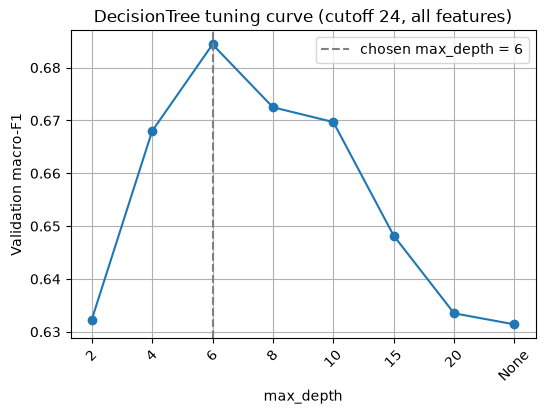

feature_set,all,background,behaviour
cutoff,,,
0,max_depth=4,max_depth=8,max_depth=6
24,max_depth=6,max_depth=2,max_depth=6
60,max_depth=8,max_depth=8,max_depth=8
120,max_depth=4,max_depth=8,max_depth=6


In [11]:
# visualize the tuning curve for the model with cutoff=24 and feature_set="all"
plot_curve("DecisionTree", dt_curve, "max_depth")

# plot the chosen max_depth for each decision tree model in FEATURE_SETS x CUTOFF_DAYS
pd.DataFrame(dt_rows).pivot(index="cutoff",
                             columns="feature_set",
                                values="best_param")

## 2.4 Random Forest

Bagged trees: low bias, reduced variance. Tune `min_samples_leaf`.

### 2.4.1 Train & tune

All 4 cutoffs × 3 feature sets; `min_samples_leaf` chosen on validation macro-F1, test scored once per cell.

In [12]:
# run experiment for random forest
# tune hyperparameter min_samples_leaf on validation set
rf_rows, rf_curve, rf_pipe = run_experiment(
    "RandomForest",
    RandomForestClassifier(random_state=SEED, n_estimators=100, n_jobs=-1),
    "min_samples_leaf", [1, 2, 5, 10, 20])

### 2.4.2 Results

Test macro-F1 by feature set × cutoff (compare with the baseline in 2.1).

In [13]:
# visualize the results of feature set x cutoff experiments results
rf_table = pd.DataFrame(rf_rows).pivot(index="cutoff",
                                        columns="feature_set",
                                        values="macro_f1")
display(rf_table)

feature_set,all,background,behaviour
cutoff,,,
0,0.6565,0.6148,0.6158
24,0.7027,0.5992,0.6830
60,0.7547,0.5993,0.7456
120,0.7969,0.5655,0.7937


### 2.4.3 Tuning curve

Validation macro-F1 against `min_samples_leaf` at cutoff 24, all features. Explains the chosen value.

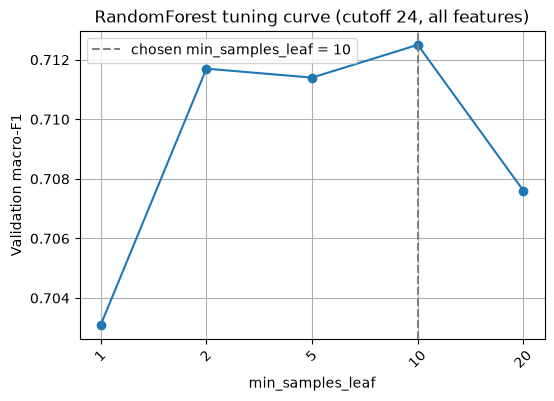

feature_set,all,background,behaviour
cutoff,,,
0,min_samples_leaf=5,min_samples_leaf=20,min_samples_leaf=5
24,min_samples_leaf=10,min_samples_leaf=20,min_samples_leaf=20
60,min_samples_leaf=2,min_samples_leaf=2,min_samples_leaf=1
120,min_samples_leaf=1,min_samples_leaf=1,min_samples_leaf=2


In [14]:
# visualize the tuning curve for the model with cutoff=24 and feature_set="all"
plot_curve("RandomForest", rf_curve, "min_samples_leaf")

# plot the chosen min_samples_leaf for each random forest model in FEATURE_SETS x CUTOFF_DAYS
pd.DataFrame(rf_rows).pivot(index="cutoff",
                             columns="feature_set",
                                values="best_param")

## 2.5 Delivery

Combines the model sections. No training happens here.

### 2.5.1 Combined results table

All rows from 2.1–2.4 (4 + 3 × 12 = 40). Handed to Section 4 for the RQ1 / RQ2 tables and figures.

In [15]:
# process the deliverables for section 4 to answer RQ1 and RQ2
results = pd.DataFrame(base_rows + log_rows + dt_rows + rf_rows)
assert len(results) == 40
display(results["model"].value_counts())

# save results to a csv file
results.to_csv("processed/results_classicalML.csv", index=False)

model
LogisticRegression    12
DecisionTree          12
RandomForest          12
Baseline               4
Name: count, dtype: int64

### 2.5.2 Best model for error analysis

The model with the highest **validation** macro-F1 at cutoff 24, all features (from each `curve`). Its `best_pipe` goes to Section 4 for the confusion matrix and specific cases.

In [16]:
# based on validation macro-F1
# find the best models' scores from each experiment
val_best = {
    "LogisticRegression": max(log_curve.values()),
    "DecisionTree": max(dt_curve.values()),
    "RandomForest": max(rf_curve.values())
}

# find the name of the best models
best_name = max(val_best, key=val_best.get)

# the best models
best_model = {
    "LogisticRegression": log_pipe,
    "DecisionTree": dt_pipe,
    "RandomForest": rf_pipe
}

# the best model pipeline
best_pipe = best_model[best_name]